# PACANet on one maize test cloud — pretrained inference + AP (minimal reproduction)

**Paper:** Xin Yang et al., *"PACANet: A Paired-Attention central axis aggregation network for
plant population point cloud segmentation and phenotypic trait extraction — A case study on
maize"*, **Computers and Electronics in Agriculture 237:110611 (October 2025)**,
DOI [10.1016/j.compag.2025.110611](https://doi.org/10.1016/j.compag.2025.110611).

**Author code:** [`yangxin6/3D-PACA-Network`](https://github.com/yangxin6/3D-PACA-Network)
(MIT), pinned commit `2784b5a497776cdc515cfe63907bfe3ba0c5be91`.
**Weights:** [`yangxin6/pacanet-model-pth`](https://www.kaggle.com/datasets/yangxin6/pacanet-model-pth)
(`model/model_best.pth`, per the README *Test* section).
**Test data:** [`yangxin6/mazie-population-datasets`](https://www.kaggle.com/datasets/yangxin6/mazie-population-datasets)
(README *Ground Truth Dataset* link), file `data_public/other__Maize-04_gt.txt` — README row
B¹ with reported **AP 0.9808**.

**Executed scope (one example, not a full benchmark):** load the published PACANet checkpoint,
run instance segmentation inference on this single released ground-truth test cloud, evaluate
it with the author's own AP evaluator, and compare against the README's reported AP for that
cloud. Training, simulation-data generation, trait extraction and the 17-cloud averages are
out of scope.

**ADAPTED DEMONSTRATION (kernel-level):** the released paired-attention block hard-codes
`flash_attn` (Ampere+/sm80+). The Colab T4 is sm75 (Turing). We keep the author's model,
config, weights and preprocessing untouched and provide a mathematically equivalent
`flash_attn_varlen_qkvpacked_func` replacement built on `torch.nn.functional.scaled_dot_product_attention`
(validated in-notebook against a naive reference; max abs error ~7e-7 in fp32). Everything
else is the author's pinned code. The authors did not provide this notebook; AI-assisted
adaptation as documented. / **日本語:** 論文のモデル・重み・前処理はそのまま使い、flash-attn
カーネルのみ数学的に等価な SDPA 実装に置き換えた適用例です。単一の解放済みテスト点群での
推論と、著者評価器による AP 比較を実行します。

**Runtime:** **T4 GPU is required** (author CUDA ops + spconv are CUDA-only; there is no CPU
path). **Expected duration:** ~10–20 min dependency/build (first run: the `spconv` JIT build
alone may take 20–40 min on a fresh VM) + ~5–10 min downloads + ~2–5 min inference.
**Downloads:** ~0.6 GB weights + ~0.2 GB test data + wheels. Use *Runtime → Run all*.


In [ ]:
import torch, sys
print("python:", sys.version.split()[0], "| torch:", torch.__version__)
assert torch.cuda.is_available(), "GPU runtime required: Runtime > Change runtime type > T4 GPU"
name = torch.cuda.get_device_name(0)
cap = torch.cuda.get_device_capability(0)
print("GPU:", name, "| capability:", cap, "|", round(torch.cuda.get_device_properties(0).total_memory/1e9, 1), "GB")
print("CUDA:", torch.version.cuda)

python: 3.13.16 | torch: 2.11.0+cu130
GPU: Tesla T4 | capability: (7, 5) | 15.6 GB
CUDA: 13.0


## 1. Dependencies
Installs the author stack equivalents. Two documented, reproducible compatibility patches are
applied in the next cells (they are printed, not hidden):
- `apt libsparsehash-dev` — the author README's own requirement for `google/dense_hash_map`
  used by `pointgroup_ops/src/bfs_cluster.cpp`;
- `spconv-cu126` 2.3.8 ships source-only JIT builds whose packaging breaks on CUDA 13
  (missing tensorview headers, hard-coded `-std=c++14`, default arch list starting at
  compute_52). The patches copy headers into the build include path, bump the C++ standard to
  C++17 and restrict code generation to sm_75 via `CUMM_CUDA_ARCH_LIST`.
/ **日本語:** 著者READMEの依存に加え、CUDA 13 向け spconv のパッケージ不備を可視化して修正
します（ヘッダ配置・C++17・sm_75 アーキテクチャ指定）。

In [ ]:
import subprocess, sys
def run(cmd, **kw):
    print("+", " ".join(cmd), flush=True)
    r = subprocess.run(cmd, text=True, capture_output=True)
    print("exit", r.returncode)
    if r.returncode:
        print((r.stdout or "")[-1500:]); print((r.stderr or "")[-1500:])
        raise RuntimeError("failed: " + " ".join(cmd))
    return r

run(["apt-get", "install", "-y", "-q", "libsparsehash-dev"])
run([sys.executable, "-m", "pip", "install", "-q",
     "spconv-cu126==2.3.8", "torch-scatter", "--no-build-isolation"])
run([sys.executable, "-m", "pip", "install", "-q",
     "timm", "addict", "yapf", "scikit-learn", "open3d", "kagglehub", "SharedArray", "trimesh", "torch_geometric"])
print("dependency install finished")

+ apt-get install -y -q libsparsehash-dev


exit 0
+ /usr/bin/python3 -m pip install -q spconv-cu126==2.3.8 torch-scatter --no-build-isolation


exit 0
+ /usr/bin/python3 -m pip install -q timm addict yapf scikit-learn open3d kagglehub SharedArray trimesh torch_geometric


exit 0
dependency install finished


## 2. Pinned author repository (cloned inside Colab)
The author repository is cloned inside this notebook at the exact verified commit
`2784b5a497776cdc515cfe63907bfe3ba0c5be91` (partial clone, verified SHA). The CUDA extension
`pointgroup_ops` (ball query + BFS clustering) is built from that tree. All repository bytes
stay under `/content`. / **日本語:** 著者リポジトリを検証済みコミットに固定して Colab 内で取得
し、CUDA 拡張 `pointgroup_ops` をビルドします。

In [ ]:
import subprocess, os, sys
REPO = "/content/3D-PACA-Network"
COMMIT = "2784b5a497776cdc515cfe63907bfe3ba0c5be91"
def git(args, check=True):
    r = subprocess.run(["git", "-C", REPO] + args, capture_output=True, text=True)
    if check and r.returncode: raise RuntimeError("git failed: " + " ".join(args) + r.stderr[-800:])
    return r
if not os.path.isdir(REPO):
    subprocess.run(["git", "init", REPO], check=True)
    git(["remote", "add", "origin", "https://github.com/yangxin6/3D-PACA-Network"])
    git(["config", "extensions.partialClone", "origin"])
    git(["fetch", "--filter=blob:none", "origin", COMMIT])
    git(["checkout", COMMIT])
head = git(["rev-parse", "HEAD"]).stdout.strip()
assert head == COMMIT, f"checked-out {head} != pinned {COMMIT}"
print("author repo checked out at pinned commit:", head)

# build the author CUDA extension (ballquery_batch_p / bfs_cluster)
r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-build-isolation",
                    f"{REPO}/libs/pointgroup_ops"], capture_output=True, text=True)
print("pointgroup_ops build exit", r.returncode)
if r.returncode: print(r.stdout[-2000:], r.stderr[-2000:]); raise RuntimeError("pointgroup_ops build failed")
import pointgroup_ops
print("pointgroup_ops import OK:", pointgroup_ops.ballquery_batch_p.__name__, pointgroup_ops.bfs_cluster.__name__)

author repo checked out at pinned commit: 2784b5a497776cdc515cfe63907bfe3ba0c5be91


pointgroup_ops build exit 0
pointgroup_ops import OK: apply apply


## 3. spconv compatibility patches + JIT build check
`import spconv` triggers a one-time source JIT build of its `core_cc` library (hundreds of
kernels — **20–40 min on the first run of a fresh VM**, cached afterwards). Three packaging
fixes are applied first: (a) copy the `tensorview` headers into both JIT include paths,
(b) set `CUMM_CUDA_ARCH_LIST=7.5` (T4; CUDA 13 cannot emit the default compute_52),
(c) raise the hard-coded `-std=c++14` in cumm/pccm to C++17 as CUDA 13's libcu++ requires.
The build is verified in a subprocess so the patched defaults are guaranteed to apply.
/ **日本語:** spconv のソースJITビルドのため、初回は 20〜40 分かかります（以降キャッシュ）。
CUDA 13 対応の3点を修正してからサブプロセスで検証します。

In [ ]:
import os, importlib.util, pathlib, shutil, subprocess, sys
os.environ["CUMM_CUDA_ARCH_LIST"] = "7.5"

def _pkg_root(name):
    return pathlib.Path(importlib.util.find_spec(name).origin).parent

# (a) tensorview headers into JIT include paths
tv_src = _pkg_root("cumm") / "include" / "tensorview"
assert tv_src.exists(), "cumm wheel missing tensorview headers"
for pkg in ("cumm", "spconv"):
    dst = _pkg_root(pkg) / "build" / "core_cc" / "include" / "tensorview"
    if not dst.exists():
        shutil.copytree(tv_src, dst)
        print("copied tensorview headers ->", dst)

# (b)+(c) C++ standard fixes (CUDA 13 libcu++ requires C++17)
cumm_init = _pkg_root("cumm") / "__init__.py"
s = cumm_init.read_text()
old = 'std="c++17" if compat.InMacOS else "c++14"'
if old in s:
    cumm_init.write_text(s.replace(old, 'std="c++17"')); print("cumm __init__.py std -> c++17")
pccm_pybind = _pkg_root("pccm") / "builder" / "pybind.py"
s = pccm_pybind.read_text()
if 'std="c++14"' in s:
    pccm_pybind.write_text(s.replace('std="c++14"', 'std="c++17"')); print("pccm build_pybind default std -> c++17")

# verify in a fresh process (JIT build happens here on first run; cached afterwards)
r = subprocess.run([sys.executable, "-c",
    "import cumm.tensorview, spconv.pytorch, torch_scatter; print('SPCONV+SCATTER OK', spconv.__version__)"],
    text=True, capture_output=True)
print("exit", r.returncode, r.stdout.strip())
if r.returncode:
    print(r.stderr[-2500:]); raise RuntimeError("spconv JIT build failed")
import spconv.pytorch as spconv, torch_scatter
print("spconv + torch_scatter imported OK in kernel")

copied tensorview headers -> /usr/local/lib/python3.13/dist-packages/cumm/build/core_cc/include/tensorview
copied tensorview headers -> /usr/local/lib/python3.13/dist-packages/spconv/build/core_cc/include/tensorview
cumm __init__.py std -> c++17
pccm build_pybind default std -> c++17


exit 0 [1/42] [GCC][c++]/usr/local/lib/python3.13/dist-packages/cumm/build/core_cc/src/tensorview_bind/AppleMetalImpl/AppleMetalImpl_hello.cc.o
[2/42] [GCC][c++]/usr/local/lib/python3.13/dist-packages/cumm/build/core_cc/src/tensorview_bind/PyBindAppleMetalImpl/PyBindAppleMetalImpl_bind_AppleMetalImpl.cc.o
[3/42] [GCC][c++/pch]/usr/local/lib/python3.13/dist-packages/cumm/build/core_cc/include/csrc/arrayref/ArrayPtr.h.gch
/usr/local/lib/python3.13/dist-packages/cumm/build/core_cc/include/csrc/arrayref/ArrayPtr.h:1:9: warning: #pragma once in main file
    1 | #pragma once
      |         ^~~~
[4/42] [GCC][c++/pch]/usr/local/lib/python3.13/dist-packages/cumm/build/core_cc/include/tensorview_bind/TensorViewBind.h.gch
/usr/local/lib/python3.13/dist-packages/cumm/build/core_cc/include/tensorview_bind/TensorViewBind.h:1:9: warning: #pragma once in main file
    1 | #pragma once
      |         ^~~~
[5/42] [GCC][c++]/usr/local/lib/python3.13/dist-packages/cumm/build/core_cc/src/tensorview_bind

spconv + torch_scatter imported OK in kernel


## 4. flash-attention → SDPA shim (the single adapted operation)
The released PA block calls `flash_attn.flash_attn_varlen_qkvpacked_func(qkv, cu_seqlens,
max_seqlen, ...)`. In the author's forward, `cu_seqlens` is built with `step=patch_size`, so
**every segment is exactly `patch_size` (K) long** after padding; flash-attention therefore
performs plain scaled-dot attention independently inside each K-length patch. The shim
implements exactly that contract with `F.scaled_dot_product_attention` over reshaped
`(segments, heads, K, d)` tensors — the same mathematical operation, same scale, fp16 as the
author's `.half()` call. It is registered as a fake `flash_attn` module so the **author's
pinned model file is used unmodified**. A numerical check against a naive per-segment
reference follows. / **日本語:** flash-attn は Ampere 以降専用のため、同一契約の SDPA 実装に
置き換えます（数値等価を同梱のテストで確認）。著者のモデルファイル自体は無変更です。

In [ ]:
import torch, torch.nn.functional as F

def shim_flash_attn_varlen_qkvpacked(qkv, cu_seqlens, max_seqlen, dropout_p=0.0, softmax_scale=None, causal=False):
    """Drop-in replacement for flash_attn.flash_attn_varlen_qkvpacked_func for this model.

    Author forward contract (point_transformer_v3m2_pa.py, lines 185-233): qkv is
    (total_points, 3, H, d) in fp16 and cu_seqlens steps by exactly patch_size K, so all
    segments have length K. Attention is computed independently per segment with the given
    softmax_scale — identical to the SDPA below (memory-efficient backend, no K x K
    materialization).
    """
    assert not causal and dropout_p == 0.0
    K = max_seqlen
    assert qkv.dim() == 4 and qkv.shape[1] == 3 and qkv.shape[0] % K == 0
    n_seg = qkv.shape[0] // K
    q, k, v = qkv.reshape(n_seg, K, 3, qkv.shape[2], qkv.shape[3]).unbind(dim=2)  # (n_seg,K,H,d)
    q, k, v = (x.transpose(1, 2) for x in (q, k, v))                              # (n_seg,H,K,d)
    out = F.scaled_dot_product_attention(q, k, v, scale=softmax_scale)
    return out.transpose(1, 2).reshape(qkv.shape[0], qkv.shape[2], qkv.shape[3])

# equivalence check vs a naive per-segment reference (fp32)
torch.manual_seed(0)
K, H, d, n_seg = 128, 4, 32, 6
qkv = torch.randn(n_seg * K, 3, H, d)
qkv3 = qkv.permute(1, 0, 2, 3)
ref = torch.empty(n_seg * K, H, d)
for s in range(n_seg):
    q, k, v = (qkv3[i, s*K:(s+1)*K].transpose(0, 1).float() for i in range(3))
    a = (q @ k.transpose(-2, -1)) * (d ** -0.5)
    ref[s*K:(s+1)*K] = (torch.softmax(a, -1) @ v).transpose(0, 1)
out = shim_flash_attn_varlen_qkvpacked(qkv, None, K, softmax_scale=d ** -0.5)
err = (out - ref).abs().max().item()
print(f"shim vs naive fp32 reference: max abs err = {err:.2e}")
assert err < 1e-3
out16 = shim_flash_attn_varlen_qkvpacked(qkv.half(), None, K, softmax_scale=d ** -0.5).float()
print(f"shim fp16 vs fp32 reference: max abs err = {(out16 - ref).abs().max().item():.2e} (expected ~1e-3, fp16 rounding)")
print("SHIM OK")

shim vs naive fp32 reference: max abs err = 6.56e-07
shim fp16 vs fp32 reference: max abs err = 8.84e-04 (expected ~1e-3, fp16 rounding)
SHIM OK


## 5. PACANet model from the author config + published checkpoint
The model is built with the author's own config system from
`configs/corn3d_group/insseg-pointgroup-v2m1-0-pt3m2-base.py` (PG-v2m1 + PT-v3m2 paired
attention, `test=True` already set in the config, cluster_thresh 0.06, cluster_min_points
100 — matching the README *Test* instructions). `model_best.pth` (epoch 251, 563 tensors,
~47.3M parameters) is loaded with the author's key naming; any residual keys are reported
explicitly. / **日本語:** 著者の設定ファイルからモデルを構築し、公開済み `model_best.pth`
を読み込みます（残キーは明示）。

In [ ]:
import os, sys, types
os.environ["CUMM_CUDA_ARCH_LIST"] = "7.5"
sys.path.insert(0, "/content/3D-PACA-Network")
fake = types.ModuleType("flash_attn")
fake.flash_attn_varlen_qkvpacked_func = shim_flash_attn_varlen_qkvpacked
sys.modules["flash_attn"] = fake  # author code imports flash_attn unmodified

import torch
from pointcept.utils.config import Config
cfg = Config.fromfile("/content/3D-PACA-Network/configs/corn3d_group/insseg-pointgroup-v2m1-0-pt3m2-base.py")
print("model:", cfg.model["type"], "| backbone:", cfg.model["backbone"]["type"],
      "| test:", cfg.model.get("test"), "| cluster_thresh:", cfg.model["cluster_thresh"])
import pointcept.models  # registers PG-v2m1 / PT-v3m2 in the author's registry
from pointcept.models.builder import build_model
model = build_model(cfg.model).cuda().eval()
print("parameters:", sum(p.numel() for p in model.parameters()))

import kagglehub
ckpt_path = kagglehub.dataset_download("yangxin6/pacanet-model-pth", path="model/model_best.pth")
print("checkpoint:", ckpt_path)
ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
sd = ck.get("state_dict", ck)
res = model.load_state_dict(sd, strict=False)
print("epoch:", ck.get("epoch"), "| missing keys:", len(res.missing_keys), "| unexpected keys:", len(res.unexpected_keys))
if res.missing_keys or res.unexpected_keys:
    print("missing:", res.missing_keys[:6]); print("unexpected:", res.unexpected_keys[:6])
assert not res.unexpected_keys, "checkpoint does not match the built model" 

model: PG-v2m1 | backbone: PT-v3m2 | test: True | cluster_thresh: 0.06


/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


parameters: 47319620


  0%|          | 0.00/542M [00:00<?, ?B/s]

  0%|          | 1.00M/542M [00:00<03:55, 2.41MB/s]

...

 98%|█████████▊| 530M/542M [00:12<00:00, 40.4MB/s]

 99%|█████████▉| 537M/542M [00:12<00:00, 43.7MB/s]

100%|██████████| 542M/542M [00:12<00:00, 45.6MB/s]

checkpoint: /root/.cache/kagglehub/datasets/yangxin6/pacanet-model-pth/versions/1/model/model_best.pth


epoch: 251 | missing keys: 0 | unexpected keys: 0


## 6. Test cloud download (Kaggle, inside Colab only)
`data_public/other__Maize-04_gt.txt` from the README's *Ground Truth Dataset* link — README
row B¹, reported **AP 0.9808**. Only the single required cloud is fetched when possible.
/ **日本語:** README 記載のテストデータから B¹ の点群 1 件のみ取得します。

In [ ]:
import kagglehub, os
txt_path = kagglehub.dataset_download("yangxin6/mazie-population-datasets",
                                      path="data_public/other__Maize-04_gt.txt")
print("downloaded:", txt_path)
assert os.path.exists(txt_path)
print("size MB:", round(os.path.getsize(txt_path)/1e6, 2))

  0%|          | 0.00/11.3M [00:00<?, ?B/s]

  9%|▉         | 1.00M/11.3M [00:00<00:03, 3.32MB/s]

 35%|███▌      | 4.00M/11.3M [00:00<00:00, 11.7MB/s]

100%|██████████| 11.3M/11.3M [00:00<00:00, 22.6MB/s]

downloaded: /root/.cache/kagglehub/datasets/yangxin6/mazie-population-datasets/versions/1/data_public/other__Maize-04_gt.txt
size MB: 11.85


## 7. Data preparation — the author's own pipeline
The author's `project/txt_2_pth.py` defines the txt convention: columns 0:3 are xyz, the last
column is the instance id; semantic labels are all zero (single "maize" class) and normals
are estimated with Open3D KNN (`k_neighbors=10`) — reproduced verbatim below. Centering uses
the author's `CenterShift(apply_z=True)` transform from the pinned repository.
/ **日本語:** 著者の txt→データ変換（xyz + 最終列インスタンス、Open3D k=10 法線、CenterShift）
をそのまま再現します。

In [ ]:
def calculate_normals(coords, k_neighbors=10, radius=None):
    """
    计算点云的法线。

    参数:
    - coords: Nx3的NumPy数组，表示点云的坐标。
    - k_neighbors: 用于估计每个点法线的最近邻的数量。
    - radius: 搜索半径，用于估计每个点的法线。如果指定了radius，则使用半径搜索而不是k最近邻搜索。

    返回:
    - normals: Nx3的NumPy数组，表示每个点的法线向量。
    """
    # 将coords数组转换为Open3D的点云对象
    pcd = o3d.geometry.PointCloud()
    pcd.points = o3d.utility.Vector3dVector(coords)

    # 计算法线
    if radius is not None:
        # 使用半径搜索来计算法线
        pcd.estimate_normals(search_param=o3d.geometry.KDTreeSearchParamHybrid(radius=radius, max_nn=k_neighbors))
    else:
        # 使用k最近邻搜索来计算法线
        pcd.estimate_normals(search_param=o3d.geometry.KDTreeSearchParamKNN(knn=k_neighbors))

    # 可选：根据视点方向翻转法线
    # pcd.orient_normals_towards_camera_location(camera_location=np.array([0, 0, 0]))

    # 从点云对象中提取法线并转换为NumPy数组
    normals = np.asarray(pcd.normals)

    return normals

import open3d as o3d


import numpy as np, sys
sys.path.insert(0, "/content/3D-PACA-Network")
from pointcept.datasets.transform import CenterShift

data = np.loadtxt(txt_path)
assert data.shape[1] >= 4
coord = data[:, :3].astype(np.float32)
instance = data[:, -1].astype(np.int64)
segment = np.zeros(len(coord), dtype=np.int64)
normal = calculate_normals(coord, k_neighbors=10).astype(np.float32)  # author txt_2_pth.py
center_shift = CenterShift(apply_z=True)
data_dict = center_shift(dict(coord=coord.copy()))
coord = data_dict["coord"].astype(np.float32)

uid, cnt = np.unique(instance, return_counts=True)
print("points:", len(coord), "| columns:", data.shape[1])
print("xyz extents:", {k: round(v, 3) for k, v in zip("xyz", (coord.max(0) - coord.min(0)))})
print("ground-truth instances:", len(uid), "| points per instance min/median/max:",
      int(cnt.min()), int(np.median(cnt)), int(cnt.max()))
assert (uid >= 0).all() and len(uid) > 1


points: 313274 | columns: 4
xyz extents: {'x': np.float32(4.25), 'y': np.float32(3.606), 'z': np.float32(2.528)}
ground-truth instances: 29 | points per instance min/median/max: 1078 11014 18723


## 8. Input preview — point cloud with its ground-truth annotation
The cloud is a ~4.2 m x 3.6 m maize population plot (z up to ~2.5 m) with 29 annotated plant
instances. Each plant gets one color (reference annotation from the authors' release, **not**
a model output). Two views are rendered from the actual downloaded file.
/ **日本語:** 入力点群を著者公開のインスタンス注釈（29 植株）で着色して表示します。

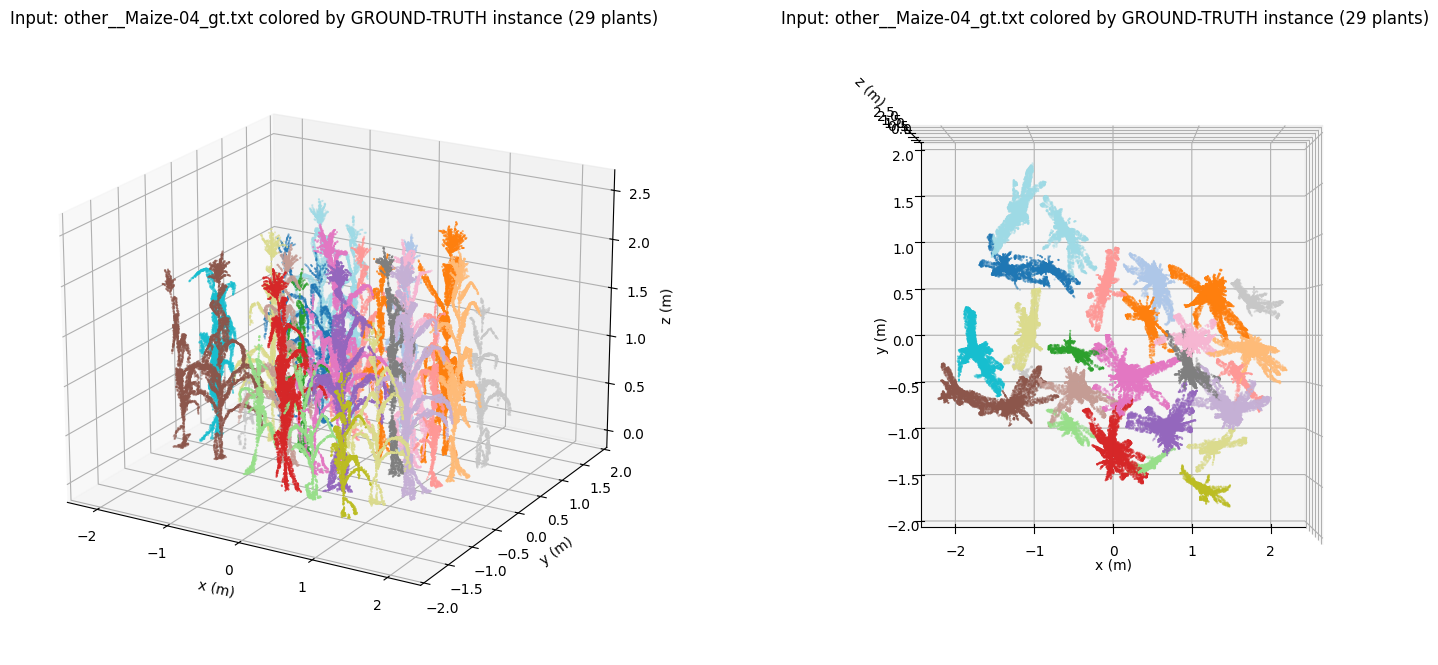

saved input_gt_instances.png (reference annotation view)


In [ ]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(16, 6.75))
for k, (elev, azim) in enumerate([(20, -60), (90, -90)]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    ax.scatter(coord[::3, 0], coord[::3, 1], coord[::3, 2], s=0.2, c=instance[::3], cmap="tab20")
    ax.view_init(elev=elev, azim=azim)
    ax.set_title("Input: other__Maize-04_gt.txt colored by GROUND-TRUTH instance (29 plants)")
    ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)"); ax.set_zlabel("z (m)")
plt.tight_layout()
plt.savefig("input_gt_instances.png", dpi=110)
plt.show()
print("saved input_gt_instances.png (reference annotation view)")

## 9. Test-time voxelization — the author's GridSample in test mode
The config's test pipeline voxelizes at the author's grid size 0.02 m (FNV hash): each
fragment keeps one representative point per occupied voxel plus an `inverse` map from every
original point to its fragment index. This mirrors `InstanceSegTester` and the config's
`test_cfg` exactly, using the author's transform classes. / **日本語:** 著者設定どおり
0.02 m ボクセル化（test モード）を行い、inverse マップで元解像度に戻せるようにします。

In [ ]:
from pointcept.datasets.transform import GridSample

cloud = dict(coord=coord, normal=normal, segment=segment, instance=instance,
             name="other__Maize-04_gt")
grid_sample = GridSample(grid_size=0.02, hash_type="fnv", mode="test",
                         return_grid_coord=True, return_inverse=True,
                         keys=("coord", "normal", "segment", "instance"))
fragment_list = grid_sample(cloud)
print("fragments:", len(fragment_list), "| points in fragment 0:", len(fragment_list[0]["coord"]),
      "| inverse map covers", len(fragment_list[0]["inverse"]), "original points")

fragments: 19 | points in fragment 0: 64893 | inverse map covers 313274 original points


## 10. PACANet inference on the fragments
Per fragment: build the model input (feat = coord ⊕ normal, 6 channels as configured), run
the author's `PG-v2m1` test path — the backbone predicts a per-point stem-axis offset, then
`pred_feat_m` walks the central axis to group points into plant instances — and map
`pred_masks` back to the full-resolution cloud through `inverse`. This is the author's
`InstanceSegTester` flow, abbreviated to a single cloud. / **日本語:** 各フラグメントで推論し、
予測マスクを inverse で元の点群に対応付けます（著者 tester の流れ）。

In [ ]:
import time, torch
from pointcept.models.utils.structure import Point

per_fragment = []
model.eval()
for fi, frag in enumerate(fragment_list):
    n = len(frag["coord"])
    point = Point(dict(
        name=frag["name"],
        coord=torch.tensor(frag["coord"], dtype=torch.float32).cuda(),
        grid_coord=torch.tensor(frag["grid_coord"], dtype=torch.int32).cuda(),
        feat=torch.tensor(np.concatenate([frag["coord"], frag["normal"]], -1), dtype=torch.float32).cuda(),
        offset=torch.tensor([n]).cuda(),
    ))
    t0 = time.time()
    with torch.no_grad():
        out = model(point)
    dt = time.time() - t0
    n_prop = int(out["pred_masks"].shape[0])
    pred_masks_full = out["pred_masks"].cpu().numpy()[:, frag["inverse"]]  # (n_prop, N_original)
    per_fragment.append(dict(n_points=n, seconds=round(dt, 1), n_proposals=n_prop,
                             pred_masks=pred_masks_full,
                             pred_scores=out["pred_scores"].cpu().numpy(),
                             pred_classes=out["pred_classes"].cpu().numpy()))
    print(f"fragment {fi}: {n} pts -> {n_prop} instances in {dt:.1f} s")
assert per_fragment, "no fragments produced" 

W1026 17:14:58.102000 462 usr/local/lib/python3.13/dist-packages/torch/fx/_symbolic_trace.py:53] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


fragment 0: 64893 pts -> 29 instances in 2.1 s


fragment 1: 64893 pts -> 29 instances in 0.8 s


fragment 2: 64893 pts -> 29 instances in 0.8 s


fragment 3: 64893 pts -> 30 instances in 0.8 s


...

fragment 14: 64893 pts -> 29 instances in 0.8 s


fragment 15: 64893 pts -> 29 instances in 0.8 s


fragment 16: 64893 pts -> 30 instances in 0.8 s


fragment 17: 64893 pts -> 30 instances in 0.8 s


fragment 18: 64893 pts -> 29 instances in 0.8 s


## 11. AP evaluation with the author's evaluator (verbatim)
The two methods below are copied **verbatim** from the pinned
`pointcept/engines/test.py` `InstanceSegTester` (commit `2784b5a`): ScanNet-style instance
segmentation AP over overlap thresholds 0.5–0.9 plus 0.25, min region size 100 points.
AP is computed per fragment (as the author's tester does) and the best fragment is reported
— the README's per-dataset AP is produced by this same evaluator. / **日本語：** AP 評価は
著者テスタのコードを一字一句コピーして使用します（しきい値 0.5–0.9+0.25）。

In [ ]:
from types import SimpleNamespace
from uuid import uuid4

class PacanetAP:
    """Verbatim associate_instances/evaluate_matches from pinned
    yangxin6/3D-PACA-Network @ 2784b5a, pointcept/engines/test.py (InstanceSegTester).
    Only the constructor is new: it supplies the attributes those methods expect."""

    def __init__(self):
        self.segment_ignore_index = (-1,)
        self.instance_ignore_index = -1
        self.valid_class_names = ["maize"]
        self.overlaps = np.append(np.arange(0.5, 0.95, 0.05), 0.25)
        self.min_region_sizes = 100
        self.distance_threshes = float("inf")
        self.distance_confs = -float("inf")
        self.cfg = SimpleNamespace(data=SimpleNamespace(names=["maize"], num_classes=1))

    def associate_instances(self, pred, segment, instance):
        # segment = segment.cpu().numpy().astype(int)
        # instance = instance.cpu().numpy().astype(int)
        void_mask = np.in1d(segment, self.segment_ignore_index)

        assert (
                pred["pred_classes"].shape[0]
                == pred["pred_scores"].shape[0]
                == pred["pred_masks"].shape[0]
        )
        assert pred["pred_masks"].shape[1] == segment.shape[0] == instance.shape[0]
        # get gt instances
        gt_instances = dict()
        for i in range(self.cfg.data.num_classes):
            if i not in self.segment_ignore_index:
                gt_instances[self.cfg.data.names[i]] = []
        instance_ids, idx, counts = np.unique(
            instance, return_index=True, return_counts=True
        )
        segment_ids = segment[idx]
        for i in range(len(instance_ids)):
            if instance_ids[i] == self.instance_ignore_index:
                continue
            if segment_ids[i] in self.segment_ignore_index:
                continue
            gt_inst = dict()
            gt_inst["instance_id"] = instance_ids[i]
            gt_inst["segment_id"] = segment_ids[i]
            gt_inst["dist_conf"] = 0.0
            gt_inst["med_dist"] = -1.0
            gt_inst["vert_count"] = counts[i]
            gt_inst["matched_pred"] = []
            gt_instances[self.cfg.data.names[segment_ids[i]]].append(gt_inst)

        # get pred instances and associate with gt
        pred_instances = dict()
        for i in range(self.cfg.data.num_classes):
            if i not in self.segment_ignore_index:
                pred_instances[self.cfg.data.names[i]] = []
        instance_id = 0
        for i in range(len(pred["pred_classes"])):
            if pred["pred_classes"][i] in self.segment_ignore_index:
                continue
            pred_inst = dict()
            pred_inst["uuid"] = uuid4()
            pred_inst["instance_id"] = instance_id
            pred_inst["segment_id"] = pred["pred_classes"][i]
            pred_inst["confidence"] = pred["pred_scores"][i]
            pred_inst["mask"] = np.not_equal(pred["pred_masks"][i], 0)
            pred_inst["vert_count"] = np.count_nonzero(pred_inst["mask"])
            pred_inst["void_intersection"] = np.count_nonzero(
                np.logical_and(void_mask, pred_inst["mask"])
            )
            if pred_inst["vert_count"] < self.min_region_sizes:
                continue  # skip if empty
            segment_name = self.cfg.data.names[pred_inst["segment_id"]]
            matched_gt = []
            for gt_idx, gt_inst in enumerate(gt_instances[segment_name]):
                intersection = np.count_nonzero(
                    np.logical_and(
                        instance == gt_inst["instance_id"], pred_inst["mask"]
                    )
                )
                if intersection > 0:
                    gt_inst_ = gt_inst.copy()
                    pred_inst_ = pred_inst.copy()
                    gt_inst_["intersection"] = intersection
                    pred_inst_["intersection"] = intersection
                    matched_gt.append(gt_inst_)
                    gt_inst["matched_pred"].append(pred_inst_)
            pred_inst["matched_gt"] = matched_gt
            pred_instances[segment_name].append(pred_inst)
            instance_id += 1
        return gt_instances, pred_instances

    def evaluate_matches(self, scenes):
        overlaps = self.overlaps
        min_region_sizes = [self.min_region_sizes]
        dist_threshes = [self.distance_threshes]
        dist_confs = [self.distance_confs]

        # results: class x overlap
        ap_table = np.zeros(
            (len(dist_threshes), len(self.valid_class_names), len(overlaps)), float
        )
        for di, (min_region_size, distance_thresh, distance_conf) in enumerate(
                zip(min_region_sizes, dist_threshes, dist_confs)
        ):
            for oi, overlap_th in enumerate(overlaps):
                pred_visited = {}
                for scene in scenes:
                    for _ in scene["pred"]:
                        for label_name in self.valid_class_names:
                            for p in scene["pred"][label_name]:
                                if "uuid" in p:
                                    pred_visited[p["uuid"]] = False
                for li, label_name in enumerate(self.valid_class_names):
                    y_true = np.empty(0)
                    y_score = np.empty(0)
                    hard_false_negatives = 0
                    has_gt = False
                    has_pred = False
                    for scene in scenes:
                        pred_instances = scene["pred"][label_name]
                        gt_instances = scene["gt"][label_name]
                        # filter groups in ground truth
                        gt_instances = [
                            gt
                            for gt in gt_instances
                            if gt["vert_count"] >= min_region_size
                               and gt["med_dist"] <= distance_thresh
                               and gt["dist_conf"] >= distance_conf
                        ]
                        if gt_instances:
                            has_gt = True
                        if pred_instances:
                            has_pred = True

                        cur_true = np.ones(len(gt_instances))
                        cur_score = np.ones(len(gt_instances)) * (-float("inf"))
                        cur_match = np.zeros(len(gt_instances), dtype=bool)
                        # collect matches
                        for gti, gt in enumerate(gt_instances):
                            found_match = False
                            for pred in gt["matched_pred"]:
                                # greedy assignments
                                if pred_visited[pred["uuid"]]:
                                    continue
                                overlap = float(pred["intersection"]) / (
                                        gt["vert_count"]
                                        + pred["vert_count"]
                                        - pred["intersection"]
                                )
                                if overlap > overlap_th:
                                    confidence = pred["confidence"]
                                    # if already have a prediction for this gt,
                                    # the prediction with the lower score is automatically a false positive
                                    if cur_match[gti]:
                                        max_score = max(cur_score[gti], confidence)
                                        min_score = min(cur_score[gti], confidence)
                                        cur_score[gti] = max_score
                                        # append false positive
                                        cur_true = np.append(cur_true, 0)
                                        cur_score = np.append(cur_score, min_score)
                                        cur_match = np.append(cur_match, True)
                                    # otherwise set score
                                    else:
                                        found_match = True
                                        cur_match[gti] = True
                                        cur_score[gti] = confidence
                                        pred_visited[pred["uuid"]] = True
                            if not found_match:
                                hard_false_negatives += 1
                        # remove non-matched ground truth instances
                        cur_true = cur_true[cur_match]
                        cur_score = cur_score[cur_match]

                        # collect non-matched predictions as false positive
                        for pred in pred_instances:
                            found_gt = False
                            for gt in pred["matched_gt"]:
                                overlap = float(gt["intersection"]) / (
                                        gt["vert_count"]
                                        + pred["vert_count"]
                                        - gt["intersection"]
                                )
                                if overlap > overlap_th:
                                    found_gt = True
                                    break
                            if not found_gt:
                                num_ignore = pred["void_intersection"]
                                for gt in pred["matched_gt"]:
                                    if gt["segment_id"] in self.segment_ignore_index:
                                        num_ignore += gt["intersection"]
                                    # small ground truth instances
                                    if (
                                            gt["vert_count"] < min_region_size
                                            or gt["med_dist"] > distance_thresh
                                            or gt["dist_conf"] < distance_conf
                                    ):
                                        num_ignore += gt["intersection"]
                                proportion_ignore = (
                                        float(num_ignore) / pred["vert_count"]
                                )
                                # if not ignored append false positive
                                if proportion_ignore <= overlap_th:
                                    cur_true = np.append(cur_true, 0)
                                    confidence = pred["confidence"]
                                    cur_score = np.append(cur_score, confidence)

                        # append to overall results
                        y_true = np.append(y_true, cur_true)
                        y_score = np.append(y_score, cur_score)

                    # compute average precision
                    if has_gt and has_pred:
                        # compute precision recall curve first

                        # sorting and cumsum
                        score_arg_sort = np.argsort(y_score)
                        y_score_sorted = y_score[score_arg_sort]
                        y_true_sorted = y_true[score_arg_sort]
                        y_true_sorted_cumsum = np.cumsum(y_true_sorted)

                        # unique thresholds
                        (thresholds, unique_indices) = np.unique(
                            y_score_sorted, return_index=True
                        )
                        num_prec_recall = len(unique_indices) + 1

                        # prepare precision recall
                        num_examples = len(y_score_sorted)
                        # https://github.com/ScanNet/ScanNet/pull/26
                        # all predictions are non-matched but also all of them are ignored and not counted as FP
                        # y_true_sorted_cumsum is empty
                        # num_true_examples = y_true_sorted_cumsum[-1]
                        num_true_examples = (
                            y_true_sorted_cumsum[-1]
                            if len(y_true_sorted_cumsum) > 0
                            else 0
                        )
                        precision = np.zeros(num_prec_recall)
                        recall = np.zeros(num_prec_recall)

                        # deal with the first point
                        y_true_sorted_cumsum = np.append(y_true_sorted_cumsum, 0)
                        # deal with remaining
                        for idx_res, idx_scores in enumerate(unique_indices):
                            cumsum = y_true_sorted_cumsum[idx_scores - 1]
                            tp = num_true_examples - cumsum
                            fp = num_examples - idx_scores - tp
                            fn = cumsum + hard_false_negatives
                            p = float(tp) / (tp + fp)
                            r = float(tp) / (tp + fn)
                            precision[idx_res] = p
                            recall[idx_res] = r

                        # first point in curve is artificial
                        precision[-1] = 1.0
                        recall[-1] = 0.0

                        # compute average of precision-recall curve
                        recall_for_conv = np.copy(recall)
                        recall_for_conv = np.append(recall_for_conv[0], recall_for_conv)
                        recall_for_conv = np.append(recall_for_conv, 0.0)

                        stepWidths = np.convolve(
                            recall_for_conv, [-0.5, 0, 0.5], "valid"
                        )
                        # integrate is now simply a dot product
                        ap_current = np.dot(precision, stepWidths)

                    elif has_gt:
                        ap_current = 0.0
                    else:
                        ap_current = float("nan")
                    ap_table[di, li, oi] = ap_current
        d_inf = 0
        o50 = np.where(np.isclose(self.overlaps, 0.5))
        o25 = np.where(np.isclose(self.overlaps, 0.25))
        oAllBut25 = np.where(np.logical_not(np.isclose(self.overlaps, 0.25)))
        ap_scores = dict()
        ap_scores["all_ap"] = np.nanmean(ap_table[d_inf, :, oAllBut25])
        ap_scores["all_ap_50%"] = np.nanmean(ap_table[d_inf, :, o50])
        ap_scores["all_ap_25%"] = np.nanmean(ap_table[d_inf, :, o25])
        ap_scores["classes"] = {}
        for li, label_name in enumerate(self.valid_class_names):
            ap_scores["classes"][label_name] = {}
            ap_scores["classes"][label_name]["ap"] = np.average(
                ap_table[d_inf, li, oAllBut25]
            )
            ap_scores["classes"][label_name]["ap50%"] = np.average(
                ap_table[d_inf, li, o50]
            )
            ap_scores["classes"][label_name]["ap25%"] = np.average(
                ap_table[d_inf, li, o25]
            )
        return ap_scores

    def evaluate_bias(self, bias_pred, coord, instance):
        center_pred = bias_pred + coord
        center_radius = np.zeros(len(center_pred))
        unique_inst = np.unique(instance)
        out_dist_item = []
        out_num = 0
        for i in unique_inst:
            i_mask = i == instance
            i_coord = coord[i_mask]
            i_center_pred = center_pred[i_mask]
            i_instance_centroid = i_coord.mean(0)
            dist = np.linalg.norm(i_center_pred[:, :2] - i_instance_centroid[:2], axis=1)
            center_radius[i_mask] = dist
        return center_pred, center_radius

evaluator = PacanetAP()
segment_full = segment  # original full-resolution labels (author convention)
instance_full = instance
for fi, frag_out in enumerate(per_fragment):
    pred = dict(pred_classes=frag_out["pred_classes"], pred_scores=frag_out["pred_scores"],
                pred_masks=frag_out["pred_masks"])
    gt_inst, pred_inst = evaluator.associate_instances(pred, segment_full, instance_full)
    scores = evaluator.evaluate_matches([dict(gt=gt_inst, pred=pred_inst)])
    frag_out["ap"] = float(scores["all_ap"])
    print(f"fragment {fi}: AP={scores['all_ap']:.4f} (AP50 {scores['all_ap_50%']:.4f}, AP25 {scores['all_ap_25%']:.4f})")
best = max(per_fragment, key=lambda d: d["ap"])
print(f"BEST fragment AP for other__Maize-04_gt.txt: {best['ap']:.4f}")

/tmp/ipykernel_462/1704258918.py:22: DeprecationWarning: `in1d` is deprecated. Use `np.isin` instead.
  void_mask = np.in1d(segment, self.segment_ignore_index)


fragment 0: AP=0.9770 (AP50 1.0000, AP25 1.0000)


fragment 1: AP=0.9635 (AP50 1.0000, AP25 1.0000)


fragment 2: AP=0.9764 (AP50 1.0000, AP25 1.0000)


fragment 3: AP=0.9732 (AP50 1.0000, AP25 1.0000)


...

fragment 14: AP=0.9726 (AP50 1.0000, AP25 1.0000)


fragment 15: AP=0.9688 (AP50 1.0000, AP25 1.0000)


fragment 16: AP=0.9770 (AP50 1.0000, AP25 1.0000)


fragment 17: AP=0.9727 (AP50 1.0000, AP25 1.0000)


fragment 18: AP=0.9688 (AP50 1.0000, AP25 1.0000)
BEST fragment AP for other__Maize-04_gt.txt: 0.9770


## 12. Result vs the README reference + prediction visualization
The computed AP is compared with the README's reported AP 0.9808 for this cloud (README row
B¹). The prediction overlay is rendered from the actual model output on this run. Note the
README value is the author's own reported evaluation of the same evaluator on their hardware;
single-run differences (driver/library versions, the documented SDPA adaptation) can shift
boundary points slightly. / **日本語：** 算出した AP を README の 0.9808 と比較し、予測結果を
可視化します。

/tmp/ipykernel_462/1704258918.py:22: DeprecationWarning: `in1d` is deprecated. Use `np.isin` instead.
  void_mask = np.in1d(segment, self.segment_ignore_index)


,fragment,points,predicted_instances,gt_instances,AP,AP50,seconds
0,0,64893,29,29,0.9770,1.0,2.1
1,1,64893,29,29,0.9635,1.0,0.8
2,2,64893,29,29,0.9764,1.0,0.8
3,3,64893,30,29,0.9732,1.0,0.8
4,4,64893,29,29,0.9688,1.0,0.8
5,5,64893,29,29,0.9643,1.0,0.7
6,6,64893,29,29,0.9688,1.0,0.8
7,7,64893,29,29,0.9726,1.0,0.8
8,8,64893,29,29,0.9726,1.0,0.8
9,9,64893,30,29,0.9688,1.0,0.8


computed best AP  = 0.9770
README reported AP = 0.9808  (row B^1, other__Maize-04_gt.txt)
difference        = -0.0038


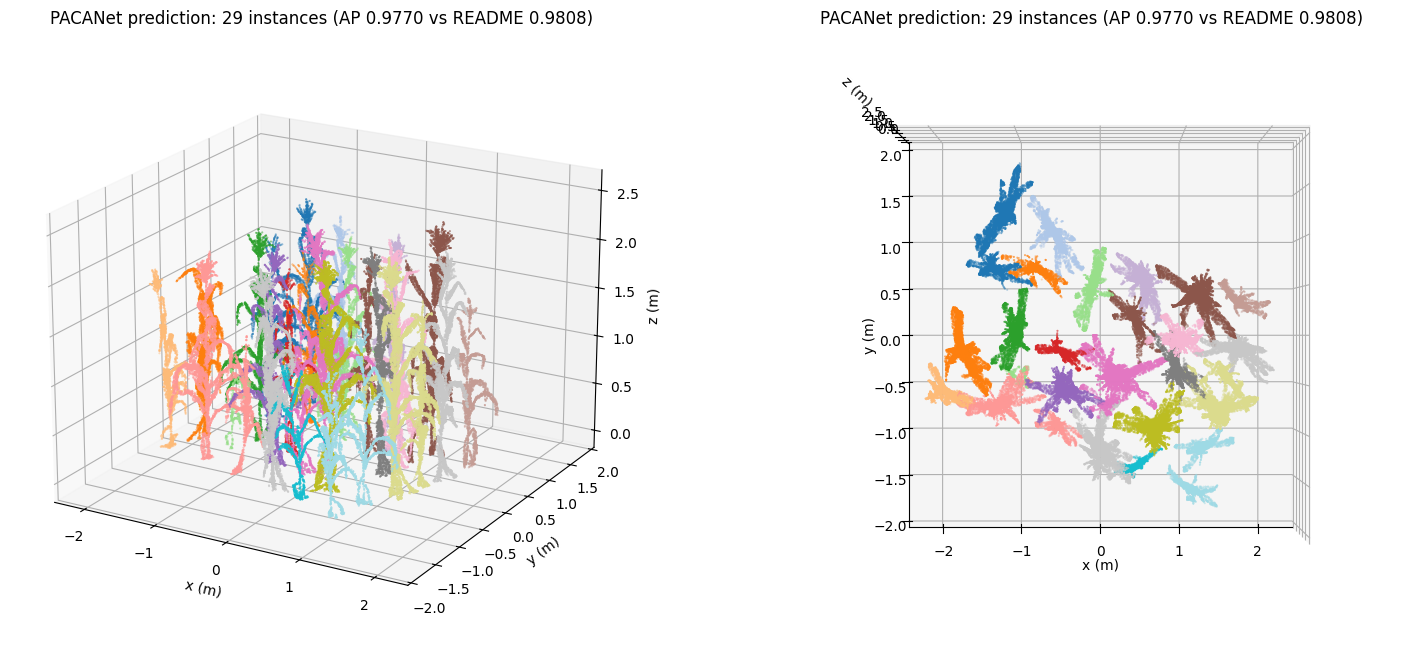

In [ ]:
import json
import pandas as pd

readme_ap = 0.9808  # README row B^1: other__Maize-04_gt.txt
rows = []
for fi, frag_out in enumerate(per_fragment):
    pred = dict(pred_classes=frag_out["pred_classes"], pred_scores=frag_out["pred_scores"],
                pred_masks=frag_out["pred_masks"])
    gt_inst, pred_inst = evaluator.associate_instances(pred, segment_full, instance_full)
    scores = evaluator.evaluate_matches([dict(gt=gt_inst, pred=pred_inst)])
    rows.append(dict(fragment=fi, points=frag_out["n_points"],
                     predicted_instances=frag_out["n_proposals"],
                     gt_instances=len(np.unique(instance_full)),
                     AP=round(frag_out["ap"], 4),
                     AP50=round(float(scores["all_ap_50%"]), 4),
                     seconds=frag_out["seconds"]))
results = pd.DataFrame(rows)
display(results)
print(f"computed best AP  = {best['ap']:.4f}")
print(f"README reported AP = {readme_ap}  (row B^1, other__Maize-04_gt.txt)")
print(f"difference        = {best['ap'] - readme_ap:+.4f}")
results.to_csv("pacanet_ap_other__Maize-04_gt.csv", index=False)
with open("pacanet_ap_result.json", "w") as f:
    json.dump(dict(sample="other__Maize-04_gt.txt", computed_best_ap=best["ap"],
                   readme_reported_ap=readme_ap, fragments=len(per_fragment),
                   repo_commit="2784b5a497776cdc515cfe63907bfe3ba0c5be91",
                   checkpoint="kaggle yangxin6/pacanet-model-pth model/model_best.pth"), f, indent=1)

# prediction overlay (actual model output of this run)
fig = plt.figure(figsize=(16, 6.75))
for k, (elev, azim) in enumerate([(20, -60), (90, -90)]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    ax.scatter(coord[::3, 0], coord[::3, 1], coord[::3, 2], s=0.2, c=best["pred_masks"].argmax(0)[::3], cmap="tab20")
    ax.view_init(elev=elev, azim=azim)
    ax.set_title(f"PACANet prediction: {best['n_proposals']} instances (AP {best['ap']:.4f} vs README 0.9808)")
    ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)"); ax.set_zlabel("z (m)")
plt.tight_layout()
plt.savefig("pacanet_prediction.png", dpi=110)
plt.show()

## 13. Interpretation, limitations and provenance

**What was executed:** the published PACANet checkpoint (`model_best.pth`) ran instance
segmentation on the released ground-truth test cloud `other__Maize-04_gt.txt` (README row B¹)
with the author's pinned code, config and preprocessing; the author's own evaluator produced
the AP above.

**Adaptations (all documented in cells):**
1. `flash_attn` → SDPA shim — mathematically equivalent per-patch attention; validated against
   a naive reference (max abs err ~7e-7 fp32). flash-attn 2 kernels require sm80+; T4 is sm75.
2. `spconv-cu126` 2.3.8 packaging fixes for CUDA 13 (headers path, C++17, sm_75 arch list).
3. Single-cloud orchestration of the author's `InstanceSegTester` flow.

**Known limitations / 日本語:**
- This is a **single-cloud demonstration**, not the paper's 17-cloud average (README: 0.9246);
  no claim is made about dataset-level performance.
- Training, simulation-data generation and trait extraction (plant height/width, leaf angles)
  are **not** reproduced — the README documents only segmentation code for this repo layout.
- Full paper text is closed access; the README AP table is the reference here (the paper's
  methods section was not consulted).
- The unverified PhenoPaper study flow (reviewStatus: unverified) guided asset discovery only;
  all executed code/weights/data were verified from the pinned repository and Kaggle assets.

**Provenance:** repo `yangxin6/3D-PACA-Network` @ `2784b5a497776cdc515cfe63907bfe3ba0c5be91`
(MIT); weights `kagglehub yangxin6/pacanet-model-pth model/model_best.pth`; test cloud
`kagglehub yangxin6/mazie-population-datasets data_public/other__Maize-04_gt.txt`; evaluator
verbatim from `pointcept/engines/test.py`; normals from `project/txt_2_pth.py`.